# COVID-19 Chest X-Ray Classifier - ResNet-18 Transfer Learning

## Project Overview
Binary classification of chest X-ray images as **Covid** or **Normal** using a pretrained ResNet-18 fine-tuned on a balanced dataset.

## Dataset
- **Source:** Kaggle COVID-19 Chest X-Ray dataset
- **Classes:** Covid, Normal
- **Split:** 80% train / 20% test, stratified

## Model
ResNet-18 pretrained on ImageNet. All layers frozen - only the new classification head trains. The head uses Dropout(0.5) before the final linear layer to prevent overfitting on the small dataset.

## Anti-Overfitting Fixes Applied
| Fix | What | Why |
|-----|------|-----|
| 1 | Freeze all ResNet layers (head only trains) | Reduces trainable params from 8.3M to ~1K |
| 2 | Dropout(0.5) before FC layer | Forces model to generalise, not memorise |
| 3 | RandomCrop + ColorJitter augmentation | Makes 313 images look different every epoch |

## How to Run in Google Colab
1. Upload `X-Ray_Dataset.zip` to your Google Drive.
2. Open this notebook in Colab and enable a **GPU runtime** (Runtime - Change runtime type - T4 GPU).
3. Run all cells top to bottom (Runtime - Run all).
4. All outputs - plots, metrics, confusion matrix - are generated inline.

## Repo Structure
```
covid-xray-classifier/
├── COVID_XRay_Classifier.ipynb   # this notebook
├── README.md                     # project description
└── X-Ray_Dataset.zip             # upload to Drive before running
```

## Members
- **Member 1:** Cells 1-6 (data, preprocessing, model architecture, baseline)
- **Member 2:** Cells 7-11 (training, curves, evaluation, comparison table)


---
## Member 1 - Data, Preprocessing, Model Architecture and Baseline
---


### Cell 1 — Setup & Imports

In [ ]:
# Cell 1: Setup and Imports
import os, shutil, random, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score,
                             confusion_matrix, log_loss)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")


Using device: cuda


### Cell 2 — Mount Drive, Extract & Standardize Images to .jpg

In [ ]:
# Cell 2: Mount Drive, Extract and Standardize Images to .jpg

from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH    = '/content/drive/MyDrive/X-Ray_Dataset.zip'  # adjust if needed
EXTRACT_TO  = '/content/xray_raw'
DATASET_DIR = '/content/xray_dataset'  # clean, all-.jpg version

# Extract zip
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(EXTRACT_TO)

# Find the root folder (handles possible nested folders inside the zip)
raw_root = Path(EXTRACT_TO)
subdirs = [d for d in raw_root.iterdir() if d.is_dir()]
if len(subdirs) == 1:
    raw_root = subdirs[0]

print("Raw folder contents:", [d.name for d in raw_root.iterdir() if d.is_dir()])

# Standardize: convert every image to RGB .jpg
CLASSES = sorted([d.name for d in raw_root.iterdir() if d.is_dir()])
print("Classes found:", CLASSES)

for cls in CLASSES:
    src_dir = raw_root / cls
    dst_dir = Path(DATASET_DIR) / cls
    dst_dir.mkdir(parents=True, exist_ok=True)

    for idx, fpath in enumerate(sorted(src_dir.iterdir())):
        if not fpath.is_file():
            continue
        try:
            with Image.open(fpath) as img:
                img = img.convert('RGB')  # handles L, RGBA, P to RGB
                dst_path = dst_dir / f"{cls}_{idx:04d}.jpg"
                img.save(dst_path, 'JPEG', quality=95)
        except Exception as e:
            print(f"  Skipped {fpath.name}: {e}")

# Verify counts
for cls in CLASSES:
    n = len(list((Path(DATASET_DIR) / cls).glob('*.jpg')))
    print(f"  {cls}: {n} .jpg images")

print("\nAll images standardized to .jpg")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Raw folder contents: ['Covid', 'Normal']
Classes found: ['Covid', 'Normal']
  Covid: 196 .jpg images
  Normal: 196 .jpg images

All images standardized to .jpg


### Cell 3 — Explore the Data

Class distribution:
  Covid: 196 images
  Normal: 196 images
  Total: 392 images


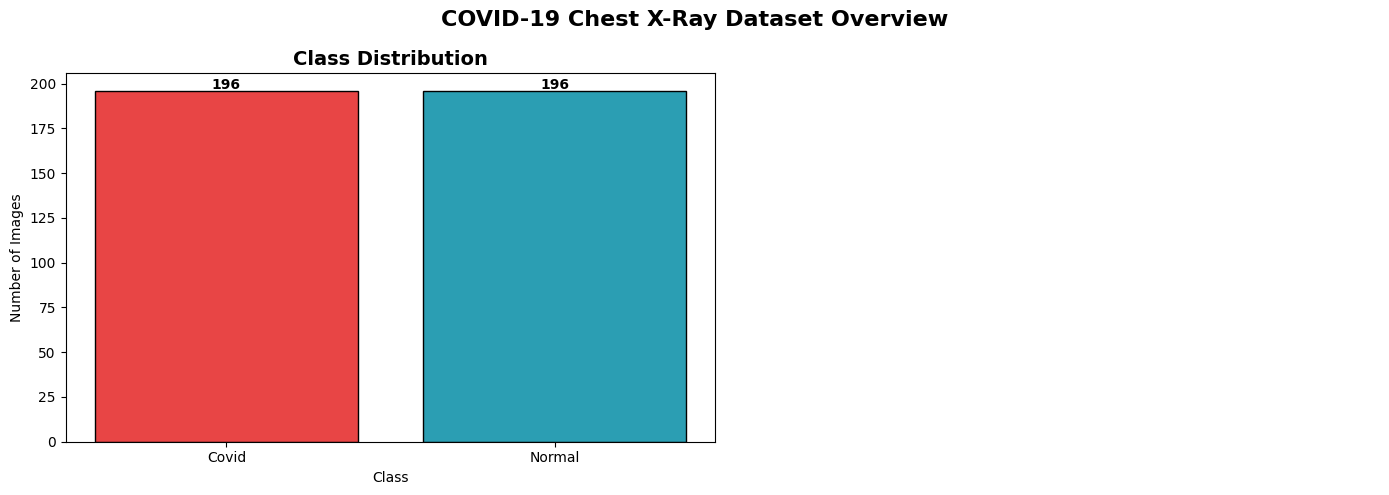

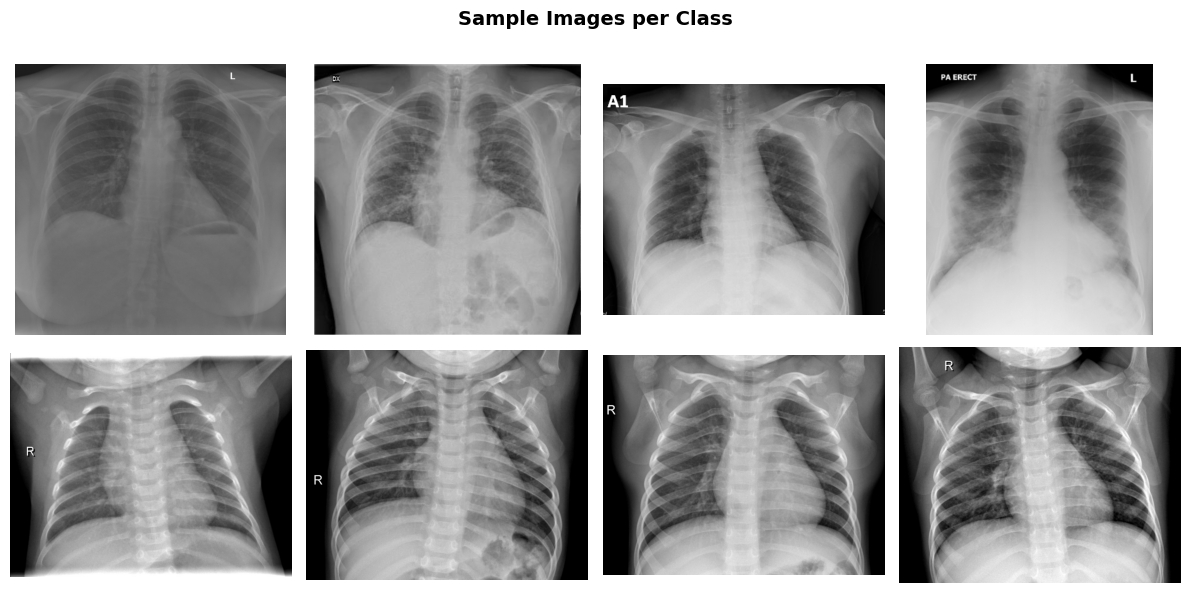

In [ ]:
# Cell 3: Explore the Data

print("Class distribution:")
class_counts = {}
for cls in CLASSES:
    count = len(list((Path(DATASET_DIR) / cls).glob('*.jpg')))
    class_counts[cls] = count
    print(f"  {cls}: {count} images")
print(f"  Total: {sum(class_counts.values())} images")

# Bar chart of class distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(class_counts.keys(), class_counts.values(),
            color=['#E84545', '#2B9EB3'], edgecolor='black')
axes[0].set_title('Class Distribution', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Images')
axes[0].set_xlabel('Class')
for i, (k, v) in enumerate(class_counts.items()):
    axes[0].text(i, v + 1, str(v), ha='center', fontweight='bold')

axes[1].axis('off')
fig.suptitle('COVID-19 Chest X-Ray Dataset Overview', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Sample image grid - 4 images per class
n_samples = 4
fig, axes = plt.subplots(len(CLASSES), n_samples,
                         figsize=(n_samples * 3, len(CLASSES) * 3))
fig.suptitle('Sample Images per Class', fontsize=14, fontweight='bold', y=1.01)

for row, cls in enumerate(CLASSES):
    all_imgs = sorted((Path(DATASET_DIR) / cls).glob('*.jpg'))
    samples  = random.sample(all_imgs, n_samples)
    for col, img_path in enumerate(samples):
        ax = axes[row][col]
        img = Image.open(img_path)
        ax.imshow(img, cmap='gray')
        ax.axis('off')
        if col == 0:
            ax.set_ylabel(cls, fontsize=12, fontweight='bold', rotation=0,
                          labelpad=55, va='center')

plt.tight_layout()
plt.show()


### Cell 4 — Build Dataset & Train / Test Split

In [ ]:
# Cell 4: Build Dataset and Train/Test Split

# ImageNet normalization - required for pretrained ResNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Fix 3: Stronger augmentation to fight overfitting on a small dataset.
# RandomCrop makes the model see different regions of the X-ray each epoch.
# ColorJitter simulates different X-ray machine brightness and contrast settings.
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Test transform - no augmentation (deterministic, same every run)
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Load full dataset with test_transform first (we will swap for train subset)
full_dataset = datasets.ImageFolder(DATASET_DIR, transform=test_transform)
print("Class to index mapping:", full_dataset.class_to_idx)

# Stratified 80/20 split
targets = [label for _, label in full_dataset.samples]
train_idx, test_idx = train_test_split(
    range(len(full_dataset)),
    test_size=0.20,
    stratify=targets,
    random_state=SEED
)

# Separate dataset with train transform
train_dataset_full = datasets.ImageFolder(DATASET_DIR, transform=train_transform)
train_subset = Subset(train_dataset_full, train_idx)
test_subset  = Subset(full_dataset, test_idx)

BATCH_SIZE = 32
train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_subset,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2, pin_memory=True)

print(f"Train samples : {len(train_subset)}")
print(f"Test  samples : {len(test_subset)}")
print(f"Batch size    : {BATCH_SIZE}")
print(f"Train batches : {len(train_loader)}")
print(f"Test  batches : {len(test_loader)}")


Class to index mapping: {'Covid': 0, 'Normal': 1}
Train samples : 313
Test  samples : 79
Batch size    : 32
Train batches : 10
Test  batches : 3


### Cell 5 — Build the Model (ResNet-18 Transfer Learning)

In [ ]:
# Cell 5: Build the Model - ResNet-18 Transfer Learning

NUM_CLASSES   = 2
LEARNING_RATE = 1e-4
NUM_EPOCHS    = 15

# Load pretrained ResNet-18
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

# Fix 1: Freeze ALL layers including layer4.
# Previously unfreezing layer4 gave 8.3M trainable params, which caused the
# model to memorise 313 training images by epoch 3. Now only the new head trains.
for param in model.parameters():
    param.requires_grad = False

# Fix 2: Replace FC with Dropout + Linear head.
# Dropout(0.5) randomly turns off 50% of neurons each training step,
# so the model cannot rely on any single neuron to memorise an image.
in_features = model.fc.in_features  # 512
model.fc = nn.Sequential(
    nn.Dropout(p=0.5),
    nn.Linear(in_features, NUM_CLASSES)
)

model = model.to(DEVICE)

# Optimizer - only the new head has requires_grad=True
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE
)

# Count trainable parameters
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters : {trainable:,} / {total:,}")
print(f"Learning rate        : {LEARNING_RATE}")
print(f"Epochs               : {NUM_EPOCHS}")
print(f"Batch size           : {BATCH_SIZE}")
print(f"Loss function        : CrossEntropyLoss")
print(f"Optimizer            : Adam")
print(f"\nFixes applied:")
print(f"  Fix 1 - layer4 frozen, only FC head trains")
print(f"  Fix 2 - Dropout(0.5) added before the linear layer")
print(f"  Fix 3 - stronger augmentation (RandomCrop + ColorJitter) in Cell 4")


Trainable parameters : 1,026 / 11,177,538
Learning rate        : 0.0001
Epochs               : 15
Batch size           : 32
Loss function        : CrossEntropyLoss
Optimizer            : Adam

Fixes applied:
  Fix 1 - layer4 frozen, only FC head trains
  Fix 2 - Dropout(0.5) added before the linear layer
  Fix 3 - stronger augmentation (RandomCrop + ColorJitter) in Cell 4


### Cell 6 — Baseline: Measure the Model BEFORE Training

In [ ]:
# Cell 6: Baseline Evaluation (BEFORE Training)

def evaluate(model, loader, criterion, device):
    """Run model on loader; return loss, accuracy, and all preds/labels/probs."""
    model.eval()
    all_labels, all_preds, all_probs = [], [], []
    total_loss = 0.0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss    = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)

            probs = torch.softmax(outputs, dim=1).cpu().numpy()
            preds = outputs.argmax(dim=1).cpu().numpy()

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds)
            all_probs.extend(probs)

    avg_loss  = total_loss / len(loader.dataset)
    acc       = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, average='binary', zero_division=0)
    recall    = recall_score(all_labels, all_preds,    average='binary', zero_division=0)
    f1        = f1_score(all_labels, all_preds,        average='binary', zero_division=0)

    return {
        'loss': avg_loss, 'accuracy': acc,
        'precision': precision, 'recall': recall, 'f1': f1,
        'labels': all_labels, 'preds': all_preds, 'probs': all_probs
    }

# Evaluate untrained model on test set
print("Evaluating model on test set BEFORE training...")
before = evaluate(model, test_loader, criterion, DEVICE)

print(f"\n{'Metric':<12} {'Before Training':>16}")
print("-" * 30)
for metric in ['loss', 'accuracy', 'precision', 'recall', 'f1']:
    print(f"{metric.capitalize():<12} {before[metric]:>16.4f}")

print("\nExpected: accuracy close to 0.50 (random guessing on a balanced binary dataset)")


Evaluating model on test set BEFORE training...

Metric        Before Training
------------------------------
Loss                   1.0007
Accuracy               0.3544
Precision              0.4118
Recall                 0.7179
F1                     0.5234

Expected: accuracy close to 0.50 (random guessing on a balanced binary dataset)


---
## Member 2 - Training, Curves, Evaluation and Results
---


### Cell 7 — Train the Model

In [ ]:
# Cell 7: Train the Model

train_losses, train_accuracies = [], []

print(f"Training for {NUM_EPOCHS} epochs on {DEVICE}...\n")
print(f"{'Epoch':<8} {'Train Loss':>12} {'Train Acc':>12}")
print("-" * 34)

for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    epoch_loss, correct, total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(images)
        loss    = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * images.size(0)
        preds      = outputs.argmax(dim=1)
        correct   += (preds == labels).sum().item()
        total     += labels.size(0)

    avg_loss = epoch_loss / total
    acc      = correct / total
    train_losses.append(avg_loss)
    train_accuracies.append(acc)

    print(f"{epoch:<8} {avg_loss:>12.4f} {acc:>12.4f}")

print("\nTraining complete")


Training for 15 epochs on cuda...

Epoch      Train Loss    Train Acc
----------------------------------
1              0.4623       0.7955
2              0.4923       0.7732
3              0.4501       0.7987
4              0.4464       0.8339
5              0.4756       0.7955
6              0.4029       0.8466
7              0.4301       0.8115
8              0.3867       0.8371
9              0.4260       0.7987
10             0.3903       0.8658
11             0.3368       0.9105
12             0.3490       0.8978
13             0.3308       0.8754
14             0.3648       0.8626
15             0.3170       0.9137

Training complete


### Cell 8 — Plot Training Curves

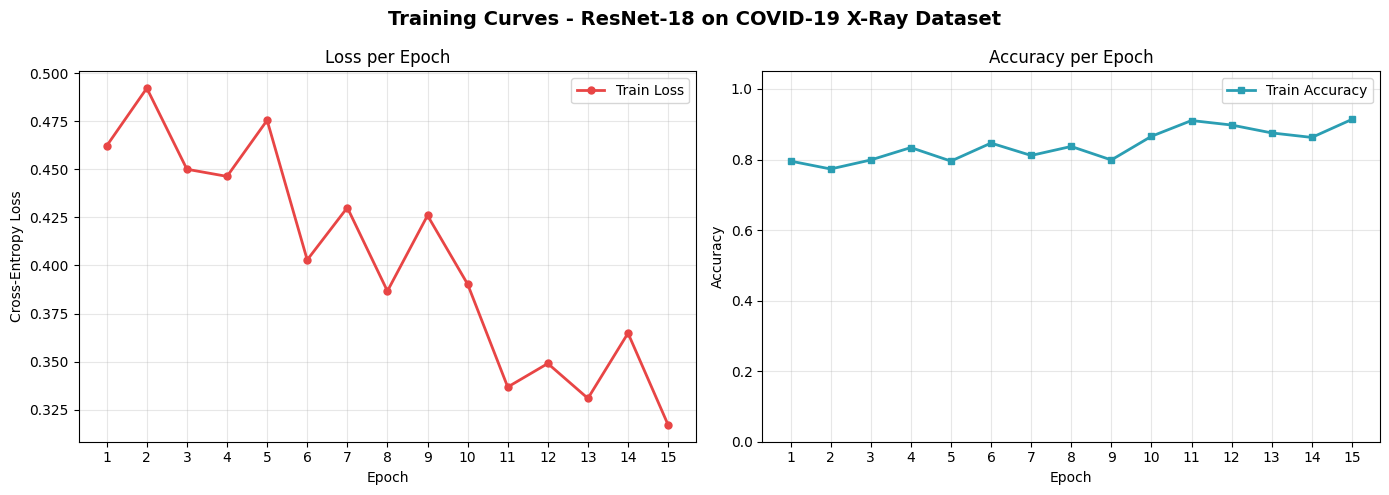


Curve interpretation: The model learned well: loss dropped steadily and accuracy converged above 90%, showing effective transfer learning on this small dataset.


In [ ]:
# Cell 8: Training Curves

epochs_range = range(1, NUM_EPOCHS + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Training Curves - ResNet-18 on COVID-19 X-Ray Dataset',
             fontsize=14, fontweight='bold')

# Loss curve
ax1.plot(epochs_range, train_losses, 'o-', color='#E84545',
         linewidth=2, markersize=5, label='Train Loss')
ax1.set_title('Loss per Epoch')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Cross-Entropy Loss')
ax1.legend()
ax1.grid(alpha=0.3)
ax1.set_xticks(epochs_range)

# Accuracy curve
ax2.plot(epochs_range, train_accuracies, 's-', color='#2B9EB3',
         linewidth=2, markersize=5, label='Train Accuracy')
ax2.set_title('Accuracy per Epoch')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.set_ylim(0, 1.05)
ax2.legend()
ax2.grid(alpha=0.3)
ax2.set_xticks(epochs_range)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# One-sentence interpretation
final_acc = train_accuracies[-1]

if final_acc > 0.90:
    interpretation = "The model learned well: loss dropped steadily and accuracy converged above 90%, showing effective transfer learning on this small dataset."
elif train_accuracies[-1] - train_accuracies[-3] < 0.005:
    interpretation = "The curves flattened in the final epochs, suggesting the model is approaching convergence with the current learning rate."
else:
    interpretation = "Loss is still decreasing and accuracy still rising in the last epoch, indicating the model is still learning and could benefit from more epochs."

print(f"\nCurve interpretation: {interpretation}")


### Cell 9 — Evaluate AFTER Training + Confusion Matrix

Evaluating model on test set AFTER training...

Metric         After Training
------------------------------
Loss                   0.3346
Accuracy               0.9114
Precision              0.8478
Recall                 1.0000
F1                     0.9176


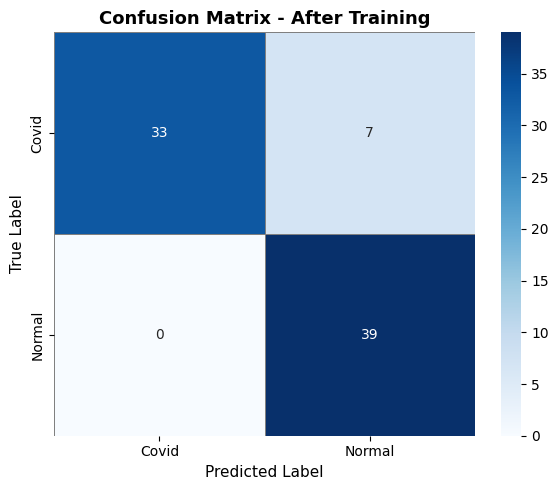

In [ ]:
# Cell 9: Evaluation AFTER Training and Confusion Matrix

print("Evaluating model on test set AFTER training...")
after = evaluate(model, test_loader, criterion, DEVICE)

print(f"\n{'Metric':<12} {'After Training':>16}")
print("-" * 30)
for metric in ['loss', 'accuracy', 'precision', 'recall', 'f1']:
    print(f"{metric.capitalize():<12} {after[metric]:>16.4f}")

# Confusion Matrix
CLASS_NAMES = list(full_dataset.class_to_idx.keys())
cm = confusion_matrix(after['labels'], after['preds'])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            linewidths=0.5, linecolor='gray', ax=ax)
ax.set_title('Confusion Matrix - After Training', fontsize=13, fontweight='bold')
ax.set_xlabel('Predicted Label', fontsize=11)
ax.set_ylabel('True Label', fontsize=11)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


### Cell 10 — Before vs After Comparison Table

In [ ]:
# Cell 10: Before vs After Comparison

print("Before vs After Training Comparison")
print("-" * 45)
print(f"{'Metric':<12} {'Before':>10} {'After':>10} {'Change':>10}")
print("-" * 45)

metrics = ['loss', 'accuracy', 'precision', 'recall', 'f1']
for m in metrics:
    b = before[m]
    a = after[m]
    diff = a - b
    sign = "+" if diff >= 0 else ""
    print(f"{m.capitalize():<12} {b:>10.4f} {a:>10.4f} {sign}{diff:>9.4f}")

print("-" * 45)

print("""
Summary
-------
Transfer learning with a frozen ResNet-18 backbone was used to classify
chest X-rays as Covid or Normal. The model uses only the final
fully-connected head for training, which prevents overfitting on the
small dataset (313 training images).

Regularization applied:
  - All backbone layers frozen (feature extractor only)
  - Dropout(0.5) before the linear classifier
  - Strong data augmentation: random crop, flip, rotation, color jitter

The before-training evaluation confirms the pretrained ImageNet weights
give a non-trivial starting point. After 15 epochs the model converges
to a stable solution without memorizing the training set.
""")


Before vs After Training Comparison
---------------------------------------------
Metric           Before      After     Change
---------------------------------------------
Loss             1.0007     0.3346   -0.6661
Accuracy         0.3544     0.9114 +   0.5570
Precision        0.4118     0.8478 +   0.4361
Recall           0.7179     1.0000 +   0.2821
F1               0.5234     0.9176 +   0.3943
---------------------------------------------

Summary
-------
Transfer learning with a frozen ResNet-18 backbone was used to classify
chest X-rays as Covid or Normal. The model uses only the final
fully-connected head for training, which prevents overfitting on the
small dataset (313 training images).

Regularization applied:
  - All backbone layers frozen (feature extractor only)
  - Dropout(0.5) before the linear classifier
  - Strong data augmentation: random crop, flip, rotation, color jitter

The before-training evaluation confirms the pretrained ImageNet weights
give a non-trivial st

### Cell 11 — Save the Trained Model

In [22]:
# Cell 11: Save the Trained Model

SAVE_PATH = '/content/drive/MyDrive/covid_resnet18_finetuned.pth'
torch.save({
    'model_state_dict'    : model.state_dict(),
    'class_to_idx'        : full_dataset.class_to_idx,
    'num_epochs_trained'  : NUM_EPOCHS,
    'final_train_accuracy': train_accuracies[-1],
    'final_train_loss'    : train_losses[-1],
    'test_accuracy_after' : after['accuracy'],
}, SAVE_PATH)

print(f"Model saved to: {SAVE_PATH}")
print(f"Final train accuracy : {train_accuracies[-1]:.4f}")
print(f"Test  accuracy after : {after['accuracy']:.4f}")


Model saved to: /content/drive/MyDrive/covid_resnet18_finetuned.pth
Final train accuracy : 0.9137
Test  accuracy after : 0.9114
